In [1]:
import numpy as np
import matplotlib.pyplot as plt

data = np.array([
    [1, 2, 3, 4, 5],
    [2, 4, 6, 8, 10],
    [3, 6, 9, 12, 15],
    [4, 8, 12, 16, 20]
])

print(data)
print("Shape:", data.shape)

[[ 1  2  3  4  5]
 [ 2  4  6  8 10]
 [ 3  6  9 12 15]
 [ 4  8 12 16 20]]
Shape: (4, 5)


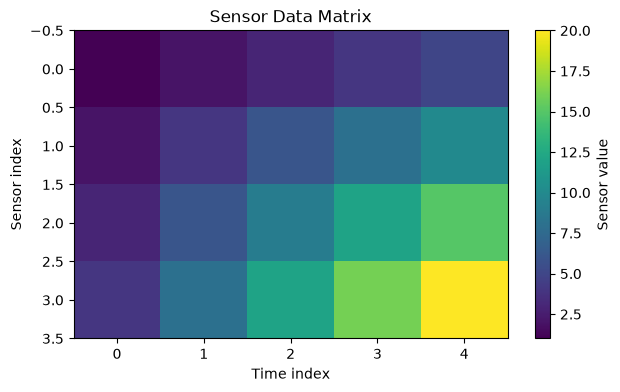

In [10]:
plt.figure(figsize=(7, 4))

plt.imshow(data, cmap="viridis", aspect="auto")

plt.colorbar(label="Sensor value")
plt.xlabel("Time index")
plt.ylabel("Sensor index")
plt.title("Sensor Data Matrix")
plt.savefig(
    "../outputs/day06_sensor_matrix.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [3]:
data_missing = data.astype(float).copy()

data_missing[2, 3] = np.nan

print(data_missing)

[[ 1.  2.  3.  4.  5.]
 [ 2.  4.  6.  8. 10.]
 [ 3.  6.  9. nan 15.]
 [ 4.  8. 12. 16. 20.]]


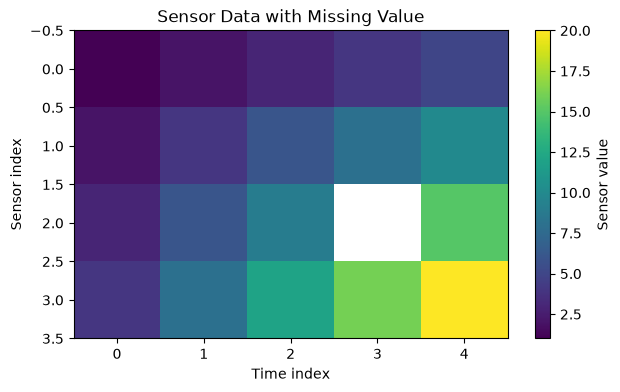

In [11]:
plt.figure(figsize=(7, 4))

plt.imshow(data_missing, cmap="viridis", aspect="auto")
plt.colorbar(label="Sensor value")

plt.xlabel("Time index")
plt.ylabel("Sensor index")
plt.title("Sensor Data with Missing Value")
plt.savefig(
    "../outputs/day06_missing_data.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [5]:
missing_mask = np.isnan(data_missing)

print(missing_mask)
print("Number of missing values:", np.sum(missing_mask))

[[False False False False False]
 [False False False False False]
 [False False False  True False]
 [False False False False False]]
Number of missing values: 1


In [7]:
import numpy as np
from scipy.interpolate import interp1d

time = np.array([0, 1, 2, 3, 4], dtype=float)
signal = np.array([2, 4, np.nan, 8, 10], dtype=float)

valid = ~np.isnan(signal)

interpolation = interp1d(
    time[valid],
    signal[valid],
    kind="linear"
)

signal_reconstructed = signal.copy()
signal_reconstructed[~valid] = interpolation(time[~valid])

print("Original signal:", signal)
print("Reconstructed signal:", signal_reconstructed)

Original signal: [ 2.  4. nan  8. 10.]
Reconstructed signal: [ 2.  4.  6.  8. 10.]


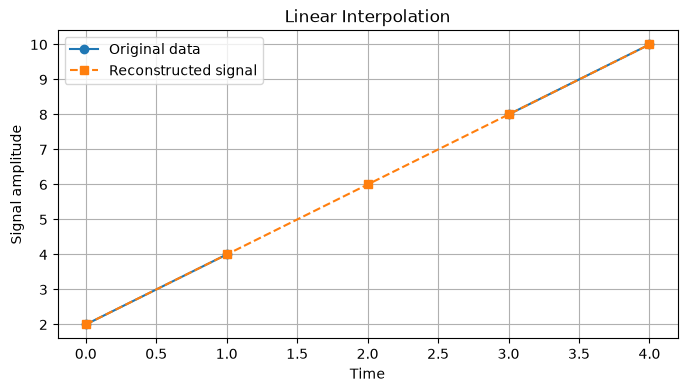

In [9]:
plt.figure(figsize=(8, 4))

plt.plot(time, signal, "o-", label="Original data")
plt.plot(
    time,
    signal_reconstructed,
    "s--",
    label="Reconstructed signal"
)

plt.xlabel("Time")
plt.ylabel("Signal amplitude")
plt.title("Linear Interpolation")
plt.grid(True)
plt.legend()
plt.savefig(
    "../outputs/day06_linear_interpolation.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()